In [1]:
import ROOT

In [2]:
c = ROOT.TCanvas("c")

In [3]:
fPS = ROOT.TFile("basic_Angle88.0000000_Pos0.0040000_Energy18600.000000.root")

In [21]:
#fPS.ls()

In [22]:
hPS = fPS.Get("histPSD_0_0")
hPS.Draw()
c.Draw()

In [14]:
import os
import ROOT
import csv

rootdir = "/home/vihanga/Desktop/Multimode Simulations/Trap_CCA_long_trap_44/results/Seed600_Angle88.0000000_Pos0.0040000_Energy18600.000000"

readout_index = 0

for root, dirs, files in os.walk(rootdir):
    for name in files:
        if name.startswith("basic_Angle") and name.endswith(".root"):
            full_path = os.path.join(root, name)
            extract_pitch_angle = name[len("basic_Angle"):len("basic_Angle")+8]
            extracting_position = name[len("basic_Angle")+14:len("basic_Angle")+19]

            f = ROOT.TFile.Open(full_path)
            if not f or f.IsZombie():
                continue

            #h_real = f.Get(f"histTSReal_0_{readout_index}") #I data
            h_imag = f.Get(f"histTSImag_0_{readout_index}") #Q data
            #if not h_real:
                #continue

            #csv_filename = f"{extract_pitch_angle}_{extracting_position}_histTSReal_0_{readout_index}.csv" #I data
            csv_filename = f"{extract_pitch_angle}_{extracting_position}_histTSImag_0_{readout_index}.csv" #Q data
            
            csv_path = os.path.join(root, csv_filename)

            with open(csv_path, mode="w", newline="") as csvfile:
                writer = csv.writer(csvfile)
                writer.writerow(["Time", "Voltage"]) 

                #for real data
                #nbins = h_real.GetNbinsX()
                #for i in range(1, nbins + 1):
                    #time = h_real.GetBinCenter(i)
                    #voltage = h_real.GetBinContent(i)
                    #writer.writerow([time, voltage])

                #for imag data
                nbins = h_imag.GetNbinsX()
                for i in range(1, nbins + 1):
                    time = h_imag.GetBinCenter(i)
                    voltage = h_imag.GetBinContent(i)
                    writer.writerow([time, voltage])

            f.Close()
            print(f"Saved {csv_path}")

Saved /home/vihanga/Desktop/Multimode Simulations/Trap_CCA_long_trap_44/results/Seed600_Angle88.0000000_Pos0.0040000_Energy18600.000000/88.00000_0.004_histTSImag_0_0.csv


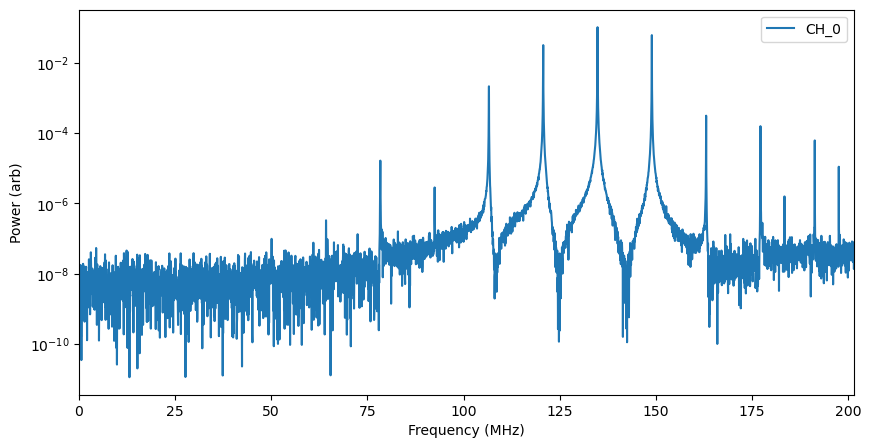

In [24]:
#Testing fft for a sum/diff readout combination
import csv
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors

rootdir = "/home/vihanga/Desktop/Multimode Simulations/Trap_CCA_long_trap_44/results/Seed600_Angle88.0000000_Pos0.0040000_Energy18600.000000"

all_pitch_angles = []
all_times = None
all_complex_voltages = {}

readout_channel = [0]
fs = 403e6

for i in readout_channel:

    real_list = []
    imag_list = []

    for root, dirs, files in os.walk(rootdir):
        for name in files:
            if name.endswith(f"TSReal_0_{i}.csv"):
                csv_path = os.path.join(root, name)

                pitch_angle = float(name[:8])
                all_pitch_angles.append(pitch_angle)

                times = []
                real_voltages = []

                with open(csv_path, "r") as csvfile:
                    reader = csv.DictReader(csvfile)
                    for row in reader:
                        times.append(float(row["Time"]))
                        real_voltages.append(float(row["Voltage"]))

                if all_times is None:
                    all_times = times

                real_list.append(real_voltages)

    for root, dirs, files in os.walk(rootdir):
        for name in files:
            if name.endswith(f"TSImag_0_{i}.csv"):
                csv_path = os.path.join(root, name)

                imag_voltages = []

                with open(csv_path, "r") as csvfile:
                    reader = csv.DictReader(csvfile)
                    for row in reader:
                        imag_voltages.append(float(row["Voltage"]))

                imag_list.append(imag_voltages)

    real_array = np.array(real_list).T
    imag_array = np.array(imag_list).T

    #sum_0_1_2_real = real_array_{0} + real_array_{1} + real_array_{2}
    #sum_0_1_2_real = np.array(sum_0_1_2).T
    
    all_complex_voltages[i] = real_array + 1j * imag_array

#CH_0
Ntime_0 = all_complex_voltages[0].shape[0]

#window = np.hanning(Ntime)[:, None]

fft_complex_voltages_0 = np.fft.fft(all_complex_voltages[0], axis=0)
freqs_0 = np.fft.fftfreq(Ntime_0, d=1/fs)

fft_complex_voltages_0 = np.fft.fftshift(fft_complex_voltages_0, axes=0)
freqs_0 = np.fft.fftshift(freqs_0)

magnitude_0 = np.abs(fft_complex_voltages_0 / 70)
power_0 = magnitude_0**2

freqs_shifted_labels = freqs_0 + fs/2 #to shift the x axis labels to plot from 0 instead of f_Nyquist/2

plt.figure(figsize=(10, 5))
plt.plot(freqs_shifted_labels / 1e6, power_0, label = "CH_0")
plt.xlabel("Frequency (MHz)")
plt.ylabel("Power (arb)")
plt.yscale('log')
plt.xlim(0, fs/2e6)
#plt.ylim(10e-13, 10e-9)
plt.legend()
#plt.axhline(4.5e-11)
#plt.axhline(4e-12)
#plt.axvline(3898072e-6, ls = '--', color = 'red')
#plt.axvline(7, color = 'red')
plt.show()

In [23]:
hPS = fPS.Get("histPSD_0_0")
hPS.Draw()
c.Draw()